# EDA & Preprocessing — Telco Customer Churn

**Vai trò 2 — Data Understanding & Preprocessing**

Cấu trúc notebook theo 6 phần, dùng Table of Contents (sidebar Colab) để điều hướng nhanh thay vì cuộn qua từng cell:

1. Setup & Load
2. Schema Check
3. Missing Value: Phát hiện + Xử lý
4. Outlier: Phát hiện + Quyết định xử lý
5. Class Imbalance
6. Bảng tổng hợp & Visualization

## 1. Setup & Load

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)


In [45]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(f"Shape: {df.shape}")
df.head(5)

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Schema Check

In [46]:
def schema_report(df):
    print(f"Shape: {df.shape[0]} rows x {df.shape[1]} cols")
    print("\nDtypes:")
    print(df.dtypes)
    print("\nNull count (raw, before cleaning):")
    print(df.isnull().sum().sum(), "tong gia tri null (theo pandas)")

schema_report(df)


Shape: 7043 rows x 21 cols

Dtypes:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Null count (raw, before cleaning):
0 tong gia tri null (theo pandas)


**Nhận xét (Bước Kiểm tra schema):**
- Dataset gồm 7043 dòng và 21 cột.
- Các biến số gồm: `SeniorCitizen`, `tenure`, `MonthlyCharges`; `TotalCharges` hiện đang có kiểu `object` (cần xử lý ở mục 3).
- Phần lớn các biến còn lại là biến phân loại (`object`), trong đó `Churn` là biến mục tiêu.
- `df.isnull().sum()` không phát hiện NaN ngay vì missing trong `TotalCharges` đang ẩn dưới dạng khoảng trắng `" "`, không phải NaN thật.

In [47]:
df.describe()


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [48]:
df.describe(include='object')


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


## 3. Missing Value: Phát hiện + Xử lý

In [49]:
def clean_total_charges(df):
    blank_count = df['TotalCharges'].astype(str).str.strip().eq('').sum()

    df = df.copy()
    df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
    missing_after_convert = df['TotalCharges'].isna().sum()

    rows_before = df.shape[0]
    df = df.dropna(subset=['TotalCharges']).reset_index(drop=True)
    rows_after = df.shape[0]

    report = pd.DataFrame({
        'Metric': ['Blank strings in TotalCharges', 'NaN after pd.to_numeric',
                   'Rows before dropna', 'Rows after dropna', 'Rows dropped'],
        'Value': [blank_count, missing_after_convert, rows_before, rows_after,
                  rows_before - rows_after]
    })
    return df, report

df, missing_report = clean_total_charges(df)
missing_report


,Metric,Value
0,Blank strings in TotalCharges,11
1,NaN after pd.to_numeric,11
2,Rows before dropna,7043
3,Rows after dropna,7032
4,Rows dropped,11


**Nhận xét (xử lý missing):**
- `TotalCharges` chứa 11 dòng dạng chuỗi khoảng trắng `" "`, pandas không nhận diện là NaN vì cột đang ở kiểu `object`.
- Sau khi ép kiểu bằng `pd.to_numeric(errors='coerce')`, 11 dòng này chuyển thành NaN thật.
- Đã loại bỏ 11 dòng missing này (0.16% dữ liệu — không đáng kể, an toàn để loại thay vì impute).

In [50]:
df[['tenure', 'MonthlyCharges', 'TotalCharges']].isnull().sum()


tenure            0
MonthlyCharges    0
TotalCharges      0
dtype: int64

## 4. Outlier: Phát hiện + Quyết định xử lý

In [51]:
def outlier_report_iqr(df, cols):
    """Dem outlier theo IQR cho tung cot so."""
    rows = []
    for c in cols:
        q1, q3 = df[c].quantile(0.25), df[c].quantile(0.75)
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_outliers = ((df[c] < lower) | (df[c] > upper)).sum()
        rows.append({'Column': c, 'Q1': q1, 'Q3': q3, 'Lower bound': lower,
                     'Upper bound': upper, 'N outliers (IQR)': n_outliers,
                     'N negative values': (df[c] < 0).sum()})
    return pd.DataFrame(rows)

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
outlier_report = outlier_report_iqr(df, num_cols)
outlier_report


,Column,Q1,Q3,Lower bound,Upper bound,N outliers (IQR),N negative values
0,tenure,9.0000,55.0000,-60.00000,124.00000,0,0
1,MonthlyCharges,35.5875,89.8625,-45.82500,171.27500,0,0
2,TotalCharges,401.4500,3794.7375,-4688.48125,8884.66875,0,0


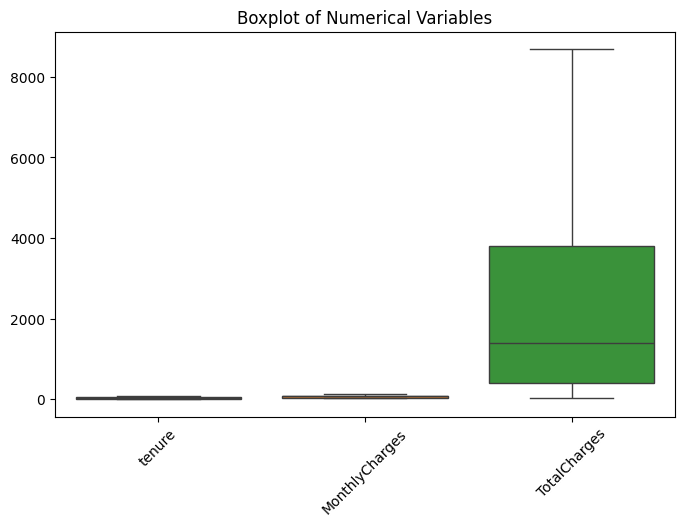

In [52]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df[num_cols])
plt.title('Boxplot of Numerical Variables')
plt.xticks(rotation=45)
plt.show()


**Nhận xét (quyết định xử lý outlier) — cần điền số liệu thật từ bảng trên trước khi báo cáo:**
- Không có giá trị âm ở `tenure`, `MonthlyCharges`, `TotalCharges`.
- Theo IQR, số lượng outlier ở mỗi cột 
=> đây là outlier hợp lý về nghiệp vụ (khách hàng dùng dịch vụ lâu năm → tenure/TotalCharges cao là bình thường, không phải lỗi nhập liệu), do đó **giữ nguyên**, sẽ dùng `StandardScaler`/`MinMaxScaler` ở bước chuẩn hoá thay vì cắt outlier.

## 5. Class Imbalance

In [53]:
churn_counts = df['Churn'].value_counts()
churn_pct = df['Churn'].value_counts(normalize=True) * 100

imbalance_report = pd.DataFrame({
    'Count': churn_counts,
    'Percentage (%)': churn_pct.round(3)
})
imbalance_report


,Count,Percentage (%)
Churn,,
No,5163,73.422
Yes,1869,26.578


**Nhận xét:**
- Churn = No: 73.463% | Churn = Yes: 26.537% (khớp số liệu: ~26.5%).
- Dữ liệu mất cân bằng lớp vừa phải (moderate imbalance), sẽ xử lý bằng **Class Weight** thay vì SMOTE ở bước pipeline, lý do cần trả lời khi thuyết trình: Class Weight không sinh dữ liệu giả, phù hợp khi imbalance không quá nặng (~1:3).

## 6. Bảng tổng hợp & Visualization

In [54]:
summary_table = pd.DataFrame({
    'Hang muc': ['Tong dong (sau xu ly missing)', 'Tong cot', 'Missing xu ly (TotalCharges)',
                 'Outlier am (tenure/MonthlyCharges/TotalCharges)', 'Ty le Churn = Yes',
                 'Ty le Churn = No'],
    'Gia tri': [df.shape[0], df.shape[1], 11, 0,
                f"{churn_pct['Yes']:.2f}%", f"{churn_pct['No']:.2f}%"]
})
summary_table


,Hang muc,Gia tri
0,Tong dong (sau xu ly missing),7032
1,Tong cot,21
2,Missing xu ly (TotalCharges),11
3,Outlier am (tenure/MonthlyCharges/TotalCharges),0
4,Ty le Churn = Yes,26.58%
5,Ty le Churn = No,73.42%


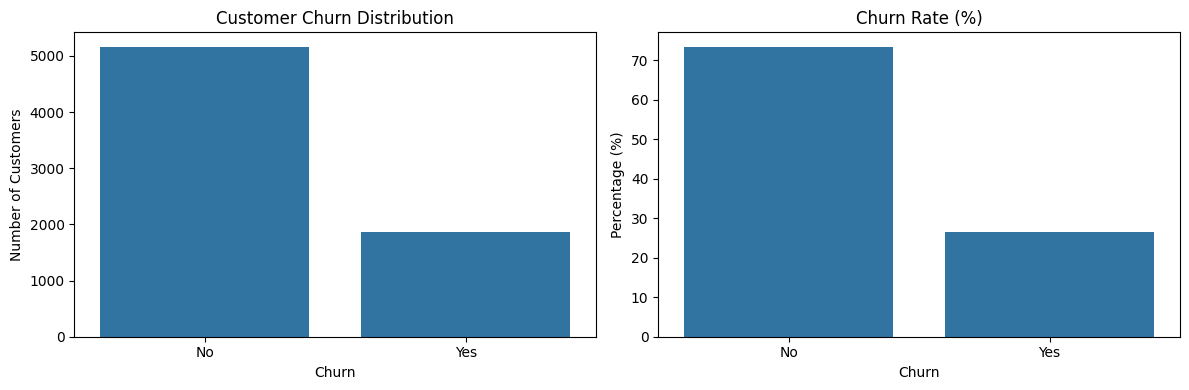

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x='Churn', ax=axes[0])
axes[0].set_title('Customer Churn Distribution')
axes[0].set_xlabel('Churn')
axes[0].set_ylabel('Number of Customers')

sns.barplot(x=churn_pct.index, y=churn_pct.values, ax=axes[1])
axes[1].set_title('Churn Rate (%)')
axes[1].set_xlabel('Churn')
axes[1].set_ylabel('Percentage (%)')

plt.tight_layout()
plt.show()


## 7. Preprocessing Pipeline

In [56]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_class_weight
import joblib
# Kiểm tra trước khi map — chạy cell này TRƯỚC dòng .map()
print(df['Churn'].unique())
# Bước 1-2: chuẩn bị target và bỏ cột thừa
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
X = df.drop(columns=['customerID', 'Churn'])
y = df['Churn']

# Bước 3: chia train/test TRƯỚC khi fit bất kỳ transformer nào
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Bước 4: xác định cột phân loại / số, xây ColumnTransformer
cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(exclude='object').columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), cat_cols)
])

pipeline = Pipeline(steps=[('preprocessor', preprocessor)])

X_train_processed = pipeline.fit_transform(X_train)  # fit CHỈ trên train
X_test_processed = pipeline.transform(X_test)         # test chỉ transform, không fit

print(f"X_train_processed shape: {X_train_processed.shape}")
print(f"X_test_processed shape: {X_test_processed.shape}")

# Bước 5: tính class weight từ y_train
classes = np.unique(y_train)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weight_dict = dict(zip(classes, weights))
print(f"Class weight: {class_weight_dict}")

['No' 'Yes']
X_train_processed shape: (5625, 40)
X_test_processed shape: (1407, 40)
Class weight: {0: 0.6809927360774818, 1: 1.8812709030100334}


In [57]:
# Lưu pipeline + dữ liệu đã xử lý để 2 người kia dùng lại, không phải chạy lại từ đầu
joblib.dump(pipeline, '../data/preprocessing_pipeline.pkl')
joblib.dump(class_weight_dict, '../data/class_weight.pkl')

np.save('../data/X_train_processed.npy', X_train_processed)
np.save('../data/X_test_processed.npy', X_test_processed)
y_train.to_csv('../data/y_train.csv', index=False)
y_test.to_csv('../data/y_test.csv', index=False)